# EDA geoespacial — avisos de Agua de Hermosillo vs. red hidrográfica

¿Existe relación espacial entre la ubicación de los avisos de Agua de Hermosillo y las características de la red hidrográfica de la ciudad?

Fuentes:
- `publicaciones_aguah.csv`: tipo de evento por publicación (`restablecimiento`, `corte_programado`, `emergencia`, `pipas`, `otro`)
- `ubicaciones_aviso.csv`: lugares mencionados en las publicaciones (nombres de colonia y cruces de calles geocodificados)
- `colonias_hermosillo.gpkg`: polígonos de colonias del DCAH, puente espacial de las menciones de colonia
- `subc_hermosillo.gpkg`: capas `hl`, `dr` y `ha` del consolidado de las 4 subcuencas (INEGI 1:50 000)

**Zona de estudio:** el círculo mínimo que envuelve los cruces geocodificados, más 2 km de margen. Cubre toda el área urbana incluyendo los huecos entre asentamientos del DCAH (los 1,467 cruces caen dentro o a ≤0.6 km de la ciudad; ninguno en Bahía de Kino ni Miguel Alemán).

Nota semántica: `hl` es la red de **drenaje natural** (cauces), no la red de agua potable. La relación se interpreta hidrológicamente (proximidad a cauces y cuerpos de agua), no como fallas de tubería.

In [157]:
import geopandas as gpd
import pandas as pd
import shapely
import matplotlib.pyplot as plt
from pathlib import Path

In [158]:
DATA = Path("../../data/processed")
SUBC = DATA / "inegi/hidrografia_hermosillo/subc_hermosillo.gpkg"

publicaciones = pd.read_csv(DATA / "aguah/publicaciones_aguah.csv")
ubicaciones = pd.read_csv(DATA / "aguah/ubicaciones_aviso.csv", dtype={"colonia_id": str})

colonias = gpd.read_file(DATA / "aguah/colonias_hermosillo.gpkg")
hl = gpd.read_file(SUBC, layer="hl")
dr = gpd.read_file(SUBC, layer="dr")
ha = gpd.read_file(SUBC, layer="ha")

print(f"{len(publicaciones)} publicaciones, {len(ubicaciones)} menciones")
print(f"{len(colonias)} colonias | hl: {len(hl)}, dr: {len(dr)}, ha: {len(ha)}")

5200 publicaciones, 16261 menciones
783 colonias | hl: 46518, dr: 36, ha: 744


## Preparación

Se une cada mención con el `event_type` de su publicación. Las menciones tienen dos formas espaciales: los **cruces geocodificados** ya traen punto (`lat`/`lon`); las **menciones de colonia** se resuelven a su polígono vía `colonia_id`. Todo se reproyecta a EPSG:6372 (metros) para medir distancias.

Sobre la confianza: `match_method` indica cómo se resolvió cada mención — `colonia_con_marcador` (el texto dice "colonia X", alta confianza), `colonia_en_catalogo` (nombre suelto emparejado al catálogo, ~74% de las menciones, menor confianza), `cruce_geocodificado` y `unmatched`.

In [159]:
METRICO = 6372  # Conica Conforme de Lambert ITRF2008, metros

menciones = ubicaciones.merge(
    publicaciones[["post_id", "event_type"]], on="post_id", how="left"
)

geocodificados = menciones["match_method"] == "cruce_geocodificado"
cruces = gpd.GeoDataFrame(
    menciones[geocodificados].reset_index(drop=True),
    geometry=gpd.points_from_xy(
        menciones.loc[geocodificados, "lon"],
        menciones.loc[geocodificados, "lat"],
    ),
    crs="EPSG:4326",
).to_crs(epsg=METRICO)

menciones_colonia = menciones[menciones["location_type"] == "colonia"]

# Zona de estudio: circulo minimo que envuelve los cruces + 2 km de margen
zona = shapely.minimum_bounding_circle(cruces.union_all()).buffer(1000)
radio_km = (zona.area / 3.141592653589793) ** 0.5 / 1000

colonias_m = colonias.to_crs(epsg=METRICO)
hl_m = hl.to_crs(epsg=METRICO)
dr_m = dr.to_crs(epsg=METRICO)
ha_m = ha.to_crs(epsg=METRICO)

hl_zona = gpd.clip(hl_m, zona)
ha_zona = gpd.clip(ha_m, zona)
dr_zona = gpd.clip(dr_m, zona)

print(f"{len(cruces)} cruces geocodificados | {len(menciones_colonia)} menciones de colonia")
print(f"Zona de estudio: radio aprox. {radio_km:.1f} km")
print(f"Dentro de la zona -> hl: {len(hl_zona)}, ha: {len(ha_zona)}, dr: {len(dr_zona)}")

1467 cruces geocodificados | 14411 menciones de colonia
Zona de estudio: radio aprox. 11.8 km
Dentro de la zona -> hl: 1158, ha: 28, dr: 4


## Resumen de las menciones

Distribución de las menciones por tipo de lugar y tipo de evento de la publicación, más el desglose por método de resolución.

In [160]:
print(
    pd.crosstab(
        menciones["event_type"], menciones["location_type"], margins=True, margins_name="total"
    )
)
print()
print(menciones["match_method"].value_counts())

location_type     colonia  cruce  total
event_type                             
corte_programado     1689     64   1753
emergencia           2519    310   2829
otro                 9537   1407  10944
pipas                  56     28     84
restablecimiento      610     41    651
total               14411   1850  16261

match_method
colonia_en_catalogo     12031
colonia_con_marcador     2380
cruce_geocodificado      1467
unmatched                 383
Name: count, dtype: int64


## Mapa: colonias y cruces mencionados vs. red hidrográfica en la zona de estudio

La red `hl` dentro de la zona, diferenciando cauces de orden bajo (<3) de los colectores principales (≥3, orden de Strahler), más los cuerpos de agua `ha` y puntos de drenaje `dr`. Los cruces geocodificados se colorean por `event_type`; cada colonia mencionada se marca con un cuadrado en su centroide (484 dentro de la zona; quedan fuera las 6 menciones rurales de Bahía de Kino y Miguel Alemán).

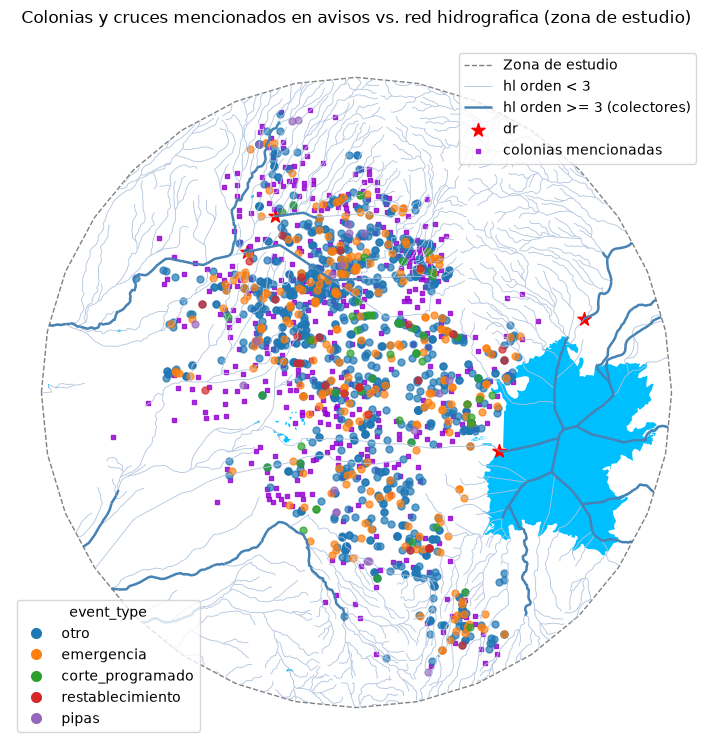

In [218]:
fig, ax = plt.subplots(figsize=(9, 9))

gpd.GeoSeries([zona], crs=hl_m.crs).boundary.plot(
    ax=ax, color="gray", linewidth=1, linestyle="--", label="Zona de estudio"
)
hl_zona[hl_zona["ORDER_1"] <= 3].plot(
    ax=ax, color="lightsteelblue", linewidth=0.6, label="hl orden < 3"
)
hl_zona[hl_zona["ORDER_1"] > 3].plot(
    ax=ax, color="steelblue", linewidth=1.8, label="hl orden >= 3 (colectores)"
)
ha_zona.plot(ax=ax, color="deepskyblue", edgecolor="none")
dr_zona.plot(ax=ax, color="red", markersize=100, marker="*", label="dr")

# colonias mencionadas dentro de la zona: un cuadrado en el centroide de cada una
mencionadas_zona = colonias_m[
    colonias_m["colonia_id"].isin(menciones_colonia["colonia_id"])
    & colonias_m.intersects(zona)
]
mencionadas_zona.centroid.plot(
    ax=ax, marker="s", color="darkviolet", markersize=8, alpha=0.8,
    label="colonias mencionadas",
)

# un color explicito por event_type para poder armar la 2a leyenda
tipos = cruces["event_type"].value_counts().index
paleta = dict(zip(tipos, plt.get_cmap("tab10").colors))
for t, c in paleta.items():
    cruces[cruces["event_type"] == t].plot(
        ax=ax, color=c, markersize=25, alpha=0.7
    )

# dos leyendas: la de la red arriba a la derecha y la de tipos abajo a la izquierda
leyenda_red = ax.legend(loc="upper right")
ax.add_artist(leyenda_red)

from matplotlib.lines import Line2D

ax.legend(
    handles=[
        Line2D(
            [0], [0], marker="o", color="none", markerfacecolor=c,
            markeredgecolor="none", markersize=8, label=t,
        )
        for t, c in paleta.items()
    ],
    loc="lower left", title="event_type",
)

ax.set_title("Colonias y cruces mencionados en avisos vs. red hidrografica (zona de estudio)")
ax.set_axis_off()
plt.show()

## Exposición por colonia

Para cada colonia de la ciudad (`locality_code == "0001"`): kilómetros de cauce `hl` que la cruzan, área de cuerpos de agua `ha` dentro, y si contiene el punto de drenaje `dr`. Se cruza con cuántas publicaciones la mencionan.

In [185]:
colonias_cd = colonias_m[colonias_m["locality_code"] == "0001"][["colonia_id", "geometry"]]

# sjoin + interseccion contra la red completa del consolidado
# (overlay descartaria los tramos lineales dentro del poligono)
pares = gpd.sjoin(hl_m[["geometry"]], colonias_cd, how="inner", predicate="intersects")
geom_colonia = pares["colonia_id"].map(colonias_cd.set_index("colonia_id")["geometry"])
tramos = pares.geometry.intersection(geom_colonia)
km_cauce = tramos.length.groupby(pares["colonia_id"]).sum() / 1000

ha_en_colonia = gpd.overlay(colonias_cd, ha_m[["geometry"]], how="intersection")
area_ha = (
    ha_en_colonia.assign(km2=lambda d: d.geometry.area / 1e6)
    .groupby("colonia_id")["km2"].sum()
)

dr_en_colonia = gpd.sjoin(
    dr_m[["geometry"]], colonias_cd, how="inner", predicate="within"
)["colonia_id"]

expo = (
    colonias_cd.set_index("colonia_id")
    .assign(km_cauce=km_cauce, area_ha_km2=area_ha)
    .fillna({"km_cauce": 0, "area_ha_km2": 0})
)
expo["tiene_dr"] = expo.index.isin(dr_en_colonia)

# Publicaciones y menciones por colonia (deduplicadas por publicacion)
expo["publicaciones"] = menciones_colonia.groupby("colonia_id")["post_id"].nunique()
expo["menciones"] = menciones_colonia.groupby("colonia_id").size()
expo[["publicaciones", "menciones"]] = expo[["publicaciones", "menciones"]].fillna(0)

print(expo[["km_cauce", "area_ha_km2", "publicaciones", "menciones"]].describe().round(2))

       km_cauce  area_ha_km2  publicaciones  menciones
count    762.00       762.00         762.00     762.00
mean       0.25         0.00          18.84      18.84
std        0.69         0.01          34.92      34.92
min        0.00         0.00           0.00       0.00
25%        0.00         0.00           0.00       0.00
50%        0.00         0.00           5.00       5.00
75%        0.28         0.00          24.00      24.00
max       10.97         0.18         389.00     389.00


In [186]:
print("Correlacion de Spearman entre exposicion y menciones:")
print(
    expo[["km_cauce", "area_ha_km2", "publicaciones", "menciones"]]
    .corr(method="spearman")
    .round(2)
)
print()
print(f"Colonias con al menos un tramo de cauce: {(expo['km_cauce'] > 0).sum()} de {len(expo)}")
print(f"Colonias con cuerpo de agua: {(expo['area_ha_km2'] > 0).sum()}")
print(f"Colonias con el punto de drenaje: {expo['tiene_dr'].sum()}")

Correlacion de Spearman entre exposicion y menciones:
               km_cauce  area_ha_km2  publicaciones  menciones
km_cauce           1.00         0.08           0.04       0.04
area_ha_km2        0.08         1.00          -0.03      -0.03
publicaciones      0.04        -0.03           1.00       1.00
menciones          0.04        -0.03           1.00       1.00

Colonias con al menos un tramo de cauce: 354 de 762
Colonias con cuerpo de agua: 14
Colonias con el punto de drenaje: 1


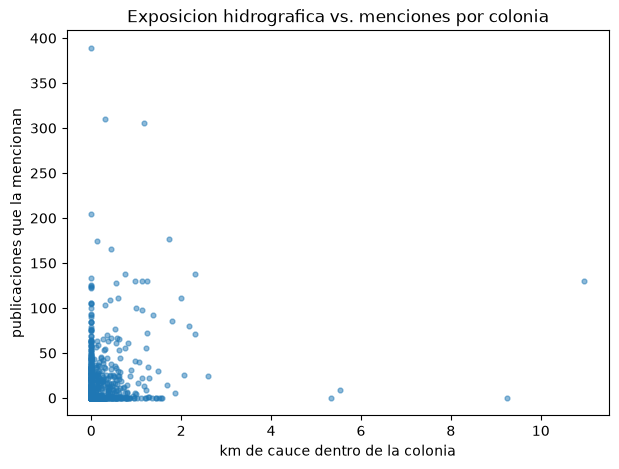

In [187]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(expo["km_cauce"], expo["publicaciones"], s=12, alpha=0.5)
ax.set_xlabel("km de cauce dentro de la colonia")
ax.set_ylabel("publicaciones que la mencionan")
ax.set_title("Exposicion hidrografica vs. menciones por colonia")
plt.show()

## Por tipo de evento

¿Se acercan más a la red los cruces de ciertos tipos de aviso? Y a nivel colonia: ¿las colonias con más emergencias tienen más exposición hidrográfica?

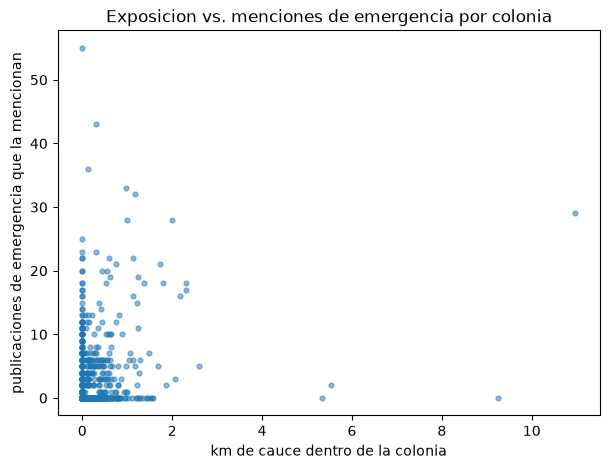

Spearman (km_cauce vs. emergencias por colonia): 0.11


In [188]:
# Emergencias por colonia vs. exposicion hidrografica
emergencias = (
    menciones_colonia[menciones_colonia["event_type"] == "emergencia"]
    .groupby("colonia_id")["post_id"].nunique()
)
expo["emergencias"] = emergencias.reindex(expo.index, fill_value=0)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(expo["km_cauce"], expo["emergencias"], s=12, alpha=0.5)
ax.set_xlabel("km de cauce dentro de la colonia")
ax.set_ylabel("publicaciones de emergencia que la mencionan")
ax.set_title("Exposicion vs. menciones de emergencia por colonia")
plt.show()

rho = expo[["km_cauce", "emergencias"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman (km_cauce vs. emergencias por colonia): {rho:.2f}")

## Limitaciones explícitas

- Las menciones son lugares nombrados en publicaciones de Facebook, no incidentes confirmados en campo; la cobertura refleja lo que Agua de Hermosillo decide publicar.
- La mayoría de las menciones de colonia se resolvieron por `colonia_en_catalogo` (nombre suelto, sin el marcador "colonia"/"fracc."), el método menos seguro; 383 menciones quedaron `unmatched`.
- Una publicación lista muchas colonias a la vez (los volantes de corte traen tablas), por lo que los conteos por colonia no equivalen a número de eventos — por eso `publicaciones` y `menciones` coinciden por colonia.
- La cercanía espacial por sí sola no implica causalidad.

## Análisis por sector (Norte / Centro / Sur)

Se divide la ciudad en los tres macro-sectores del PDU asignados en la libreta `05` (`notebook_experimentation_data/colonias_hermosillo.csv`) y se repite el cruce exposición hidrográfica ↔ menciones **por sector**.

In [203]:
sectores = pd.read_csv(
    Path("notebook_experimentation_data/colonias_hermosillo.csv"),
    usecols=["colonia_id", "sector"],
    dtype={"colonia_id": str},
)

# sector por colonia (expo ya trae km_cauce, area_ha_km2, menciones, emergencias)
expo_sector = expo.join(sectores.set_index("colonia_id")["sector"])
print(f"colonias con sector: {expo_sector['sector'].notna().sum()} de {len(expo_sector)}")

# sector por cruce: el punto cae dentro del poligono de la colonia
colonias_sector = colonias_cd.merge(sectores, on="colonia_id", how="left")
cruces = gpd.sjoin(
    cruces, colonias_sector[["sector", "geometry"]], how="left", predicate="within"
).drop(columns="index_right")
cruces = cruces[~cruces.index.duplicated(keep="first")]  # borde entre colonias

print(f"cruces dentro de una colonia con sector: {cruces['sector'].notna().sum()} de {len(cruces)}")

colonias con sector: 762 de 762
cruces dentro de una colonia con sector: 1370 de 1467


In [204]:
# exposicion hidrografica y menciones agregadas por sector
por_sector = (
    expo_sector.dropna(subset=["sector"])
    .groupby("sector")
    .agg(
        colonias=("sector", "size"),
        area_km2=("geometry", lambda g: g.area.sum() / 1e6),
        km_cauce=("km_cauce", "sum"),
        area_ha_km2=("area_ha_km2", "sum"),
        publicaciones=("publicaciones", "sum"),
        menciones=("menciones", "sum"),
        emergencias=("emergencias", "sum"),
    )
)
por_sector["cruces"] = cruces["sector"].value_counts()
por_sector["km_cauce_por_km2"] = por_sector["km_cauce"] / por_sector["area_km2"]
por_sector["ha_por_km2"] = por_sector["area_ha_km2"] / por_sector["area_km2"]
por_sector["menciones_por_km2"] = por_sector["menciones"] / por_sector["area_km2"]
por_sector["cruces_por_km_cauce"] = por_sector["cruces"] / por_sector["km_cauce"]
por_sector.round(2)

,colonias,area_km2,km_cauce,area_ha_km2,publicaciones,menciones,emergencias,cruces,km_cauce_por_km2,ha_por_km2,menciones_por_km2,cruces_por_km_cauce
sector,,,,,,,,,,,,
Centro,178,36.91,11.37,0.14,3353.0,3353.0,564,422,0.31,0.0,90.83,37.11
Norte,398,55.58,112.44,0.21,8955.0,8955.0,1628,665,2.02,0.0,161.13,5.91
Sur,186,39.95,64.74,0.06,2045.0,2045.0,322,283,1.62,0.0,51.19,4.37


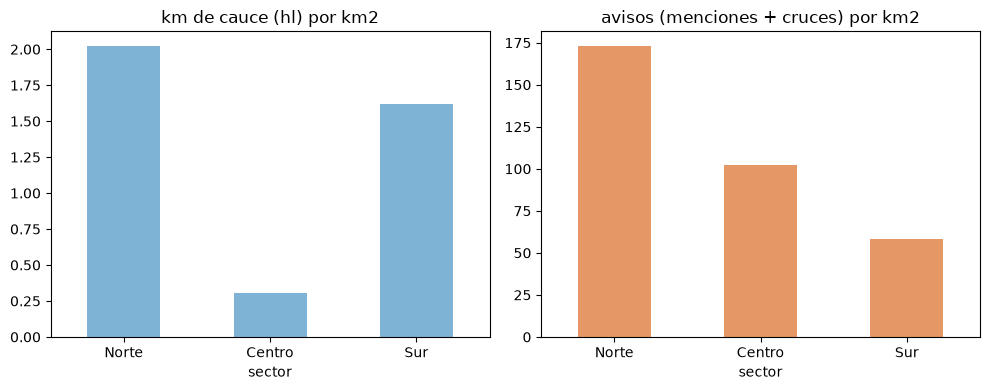

In [205]:
# comparativo por sector: exposicion normalizada vs. actividad de avisos
# avisos = menciones de colonia + cruces geocodificados mencionados
por_sector["avisos_por_km2"] = (
    por_sector["menciones"] + por_sector["cruces"]
) / por_sector["area_km2"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

por_sector["km_cauce_por_km2"].reindex(["Norte", "Centro", "Sur"]).plot.bar(
    ax=axes[0], rot=0, color="#7fb3d5"
)
axes[0].set_title("km de cauce (hl) por km2")
por_sector["avisos_por_km2"].reindex(["Norte", "Centro", "Sur"]).plot.bar(
    ax=axes[1], rot=0, color="#e59866"
)
axes[1].set_title("avisos (menciones + cruces) por km2")

plt.tight_layout()
plt.show()

Spearman exposicion vs. menciones por sector (por colonia):
  Norte: km_cauce rho=0.06  (398 colonias)
  Centro: km_cauce rho=0.01  (178 colonias)
  Sur: km_cauce rho=-0.01  (186 colonias)


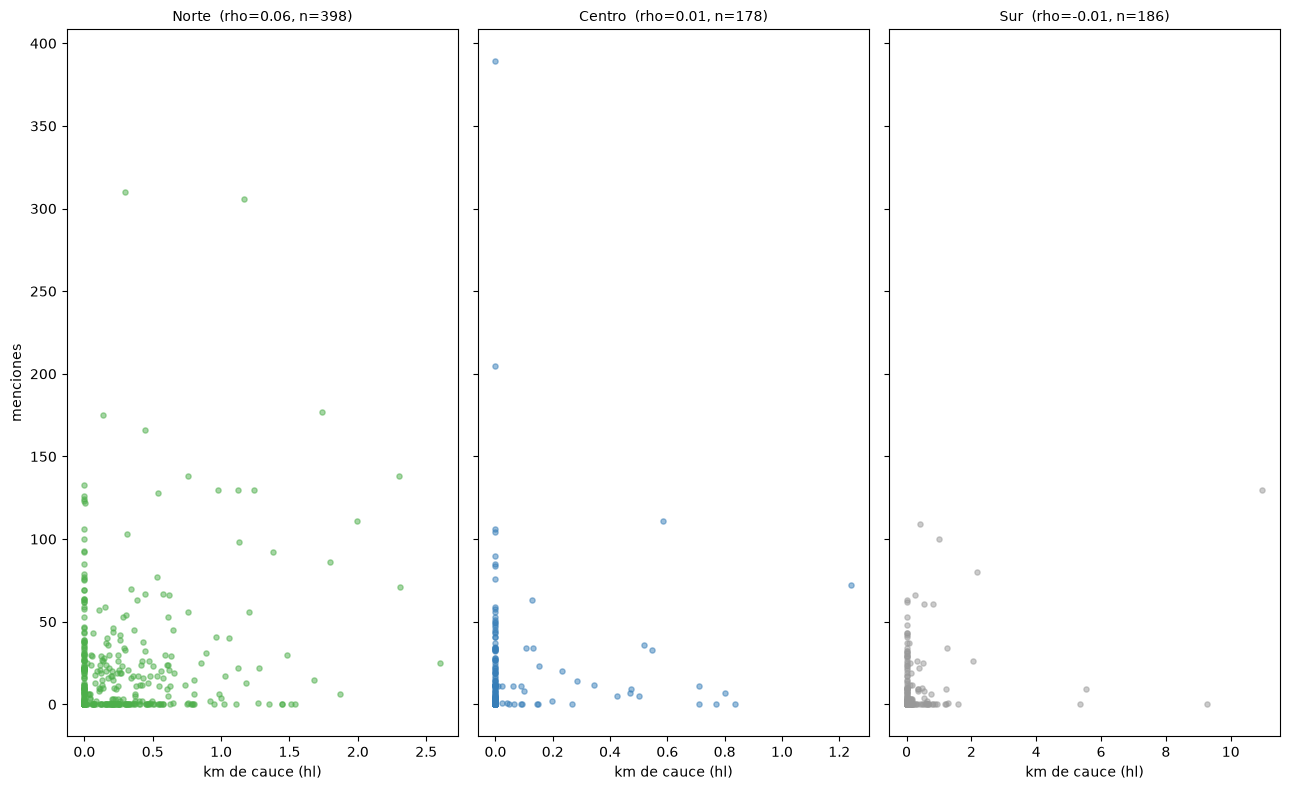

In [206]:
# exposicion vs. menciones por colonia, un panel por sector: si la pendiente
# cambia entre sectores, la relacion aviso~hidrografia no es uniforme
colores_sector = {"Norte": "#4daf4a", "Centro": "#377eb8", "Sur": "#999999"}
orden = ["Norte", "Centro", "Sur"]
#exposiciones = [("km_cauce", "km de cauce (hl)"), ("area_ha_km2", "cuerpos de agua (ha), km2")]
exposiciones = [("km_cauce", "km de cauce (hl)")]

fig, axes = plt.subplots(1, 3, figsize=(13, 8), sharey="row")

print("Spearman exposicion vs. menciones por sector (por colonia):")
for j, s in enumerate(orden):
    d = expo_sector[expo_sector["sector"] == s]
    for i, (exposicion, etiqueta) in enumerate(exposiciones):
        ax = axes[j]
        ax.scatter(d[exposicion], d["menciones"], s=14, alpha=0.5, color=colores_sector[s])
        rho = d[[exposicion, "menciones"]].corr(method="spearman").iloc[0, 1]
        ax.set_title(f"{s}  (rho={rho:.2f}, n={len(d)})", fontsize=10)
        ax.set_xlabel(etiqueta)
        if j == 0:
            ax.set_ylabel("menciones")
        print(f"  {s}: {exposicion} rho={rho:.2f}  ({len(d)} colonias)")

plt.tight_layout()
plt.show()

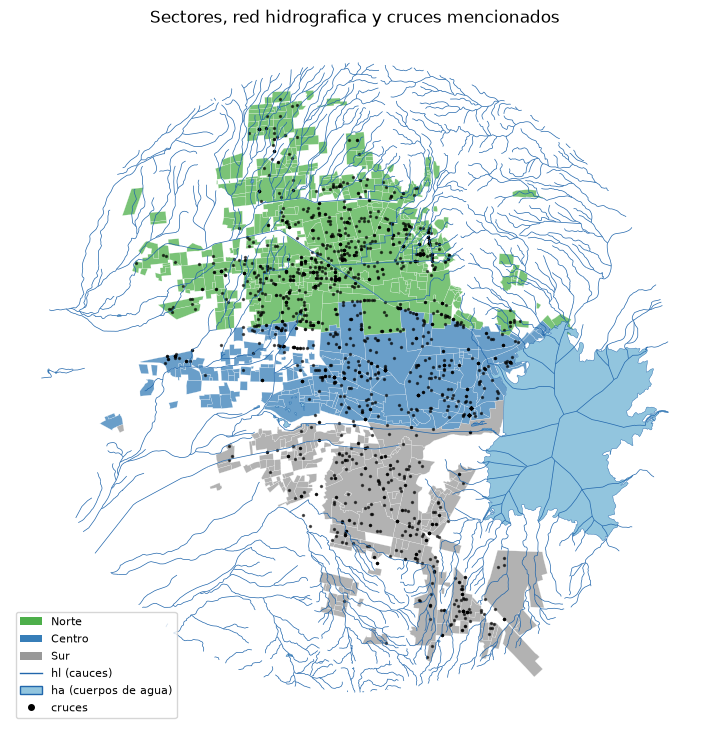

In [207]:
# mapa: colonias por sector, red hidrografica y cruces mencionados
fig, ax = plt.subplots(figsize=(9, 9))
for s, c in colores_sector.items():
    expo_sector[expo_sector["sector"] == s].plot(
        ax=ax, color=c, edgecolor="white", linewidth=0.2, alpha=0.75
    )
hl_zona.plot(ax=ax, color="#2166ac", linewidth=0.5)
ha_zona.plot(ax=ax, color="#92c5de", edgecolor="#2166ac", linewidth=0.3)
cruces.plot(ax=ax, color="black", markersize=2, alpha=0.6)

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ax.legend(
    handles=[
        *[Patch(facecolor=c, label=s) for s, c in colores_sector.items()],
        Line2D([0], [0], color="#2166ac", lw=1, label="hl (cauces)"),
        Patch(facecolor="#92c5de", edgecolor="#2166ac", label="ha (cuerpos de agua)"),
        Line2D([0], [0], marker="o", color="black", lw=0, markersize=4, label="cruces"),
    ],
    loc="lower left",
    fontsize=8,
)
ax.set_title("Sectores, red hidrografica y cruces mencionados")
ax.set_axis_off()
plt.show()

## Preguntas por sector

Cuatro métricas comparables entre Norte, Centro y Sur:

1. **Avisos por densidad de cauce** — (cruces + menciones) / (km de cauce por km²): ¿dónde genera más avisos la misma densidad de red `hl`?
2. **Distancia mínima promedio aviso↔cauce** — ¿qué tan cerca de un cauce `hl` caen los cruces mencionados en cada sector?
3. **Distancia mínima promedio aviso↔cuerpo de agua** — lo mismo contra la capa `ha`.
4. **Avisos por km de colector** — (cruces + menciones) / km de cauce con `ORDER_1 > 3` (colectores principales): ¿los avisos se concentran donde hay cauce mayor?

Nota: en el Centro `km_cauce_por_km2` es muy chico (0.31) — el denominador pequeño infla las razones 1 y 4; leer como "los avisos del Centro no dependen de la red `hl`".

In [208]:
# preparacion: distancia de cada cruce a las capas hidrograficas
# (recuperada del commit 42b1e42 - se habia borrado junto con las
#  variables sector/aviso de las preguntas por sector)
def distancia_a(puntos, capa, columna):
    unidos = gpd.sjoin_nearest(
        puntos, capa[["geometry"]], how="left", distance_col=columna
    )
    # sjoin_nearest duplica la fila si el punto empata entre dos geometrias
    return unidos[~unidos.index.duplicated(keep="first")].drop(columns="index_right")

cruces = cruces.pipe(distancia_a, hl_zona, "dist_hl_m")
cruces = cruces.pipe(distancia_a, ha_zona, "dist_ha_m")
cruces = cruces.pipe(distancia_a, dr_zona, "dist_dr_m")
cruces = cruces.pipe(
    distancia_a, hl_zona[hl_zona["ORDER_1"] >= 4], "dist_hl_orden4_m"
)

print(cruces[["dist_hl_m", "dist_ha_m", "dist_dr_m", "dist_hl_orden4_m"]].describe().round(1))

       dist_hl_m  dist_ha_m  dist_dr_m  dist_hl_orden4_m
count     1467.0     1467.0     1467.0            1467.0
mean       543.9     2890.3     4110.9            2169.4
std        527.2     1438.9     1748.2            1214.1
min          0.1       70.1       10.7               7.3
25%        133.9     1822.4     2799.2            1195.2
50%        377.8     2928.7     4103.9            2173.7
75%        791.8     3954.1     5497.3            3134.2
max       2361.0     6085.4     8880.4            5096.2


        avisos  km_cauce_por_km2  avisos_por_densidad_cauce
sector                                                     
Centro  3775.0               0.3                    12254.5
Norte   9620.0               2.0                     4754.7
Sur     2328.0               1.6                     1436.6
(inf = el sector no tiene cauce dentro de sus colonias, la razon no es finita)


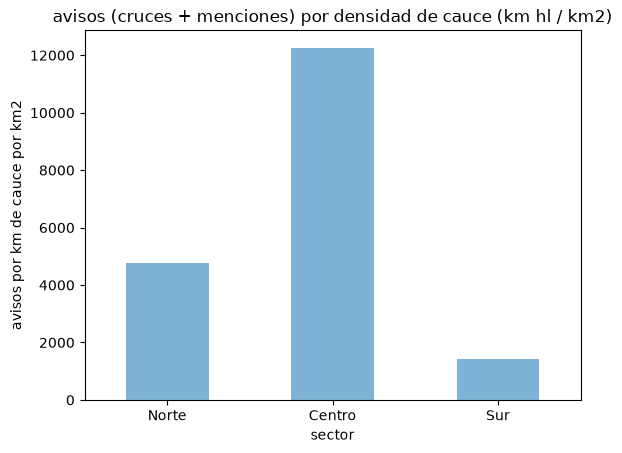

In [209]:
# P1: (cruces + menciones) / (km de cauce por km2) por sector
# avisos = menciones de colonia + cruces geocodificados
por_sector["avisos"] = por_sector["menciones"] + por_sector["cruces"]
por_sector["avisos_por_densidad_cauce"] = (
    por_sector["avisos"] / por_sector["km_cauce_por_km2"]
)

print(por_sector[["avisos", "km_cauce_por_km2", "avisos_por_densidad_cauce"]].round(1))
print("(inf = el sector no tiene cauce dentro de sus colonias, la razon no es finita)")

por_sector["avisos_por_densidad_cauce"].replace(
    float("inf"), float("nan")
).reindex(orden).plot.bar(rot=0, color="#7fb3d5")
plt.title("avisos (cruces + menciones) por densidad de cauce (km hl / km2)")
plt.ylabel("avisos por km de cauce por km2")
plt.show()

Distancia al cauce hl mas cercano (m):
        count    mean  median
sector                       
Centro    422  1019.0   894.0
Norte     665   328.0   257.0
Sur       283   482.0   334.0


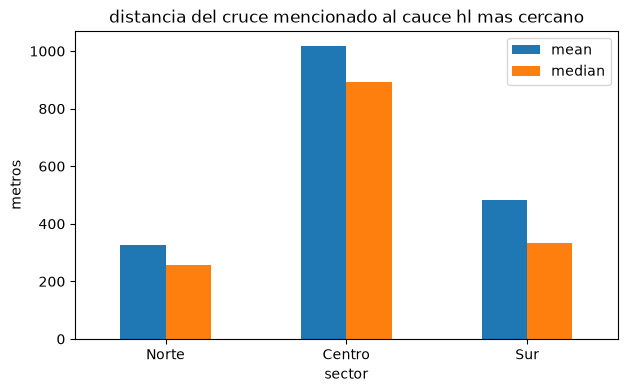

In [210]:
# P2: distancia minima promedio aviso <-> cauce (hl) por sector
dist_hl = cruces.groupby("sector")["dist_hl_m"].agg(
    ["count", "mean", "median"]
).round(0)
print("Distancia al cauce hl mas cercano (m):")
print(dist_hl)

fig, ax = plt.subplots(figsize=(7, 4))
dist_hl[["mean", "median"]].reindex(orden).plot.bar(ax=ax, rot=0)
ax.set_title("distancia del cruce mencionado al cauce hl mas cercano")
ax.set_ylabel("metros")
plt.show()

In [ ]:
## Análisis temporal: ¿los avisos se concentran en la temporada de lluvias?

El conteo es **por mención, no por publicación**: cada colonia aporta a su propio sector, así que un aviso que menciona colonias en varios sectores cuenta en cada uno (aunque el post sea el mismo). Se incluyen los 3 sectores.

**Hipótesis:** la mayoría de los avisos caen entre **agosto y octubre** — la temporada de lluvias en Hermosillo, cuando los cauces se activan.

        avisos  km_colector  avisos_por_km_colector
sector                                             
Centro  3775.0          0.0                     inf
Norte   9620.0          9.2                  1042.5
Sur     2328.0          2.8                   835.9
(inf = el sector no tiene ningun km de colector dentro de sus colonias)


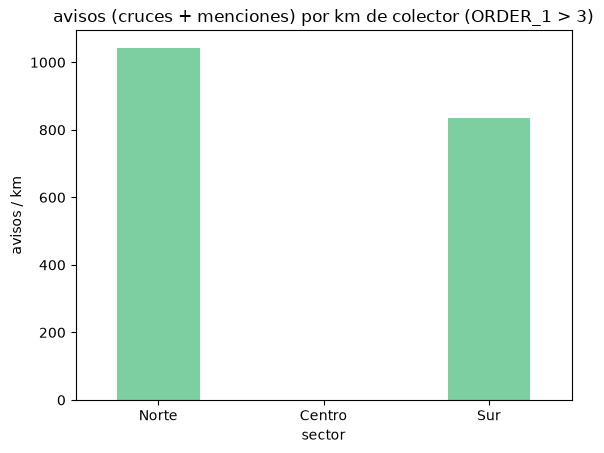

In [219]:
# P4: (cruces + menciones) / km de cauce con ORDER_1 > 3 (colectores) por sector
# misma logica que km_cauce: solo tramos dentro de los poligonos de colonias
poligonos_sector = colonias_sector.dropna(subset=["sector"]).dissolve(by="sector")
colectores = hl_m[hl_m["ORDER_1"] > 3][["geometry"]]
km_colector = {
    s: gpd.clip(colectores, geom).length.sum() / 1000
    for s, geom in poligonos_sector.geometry.items()
}

por_sector["km_colector"] = pd.Series(km_colector)
por_sector["avisos_por_km_colector"] = por_sector["avisos"] / por_sector["km_colector"]

print(por_sector[["avisos", "km_colector", "avisos_por_km_colector"]].round(1))
print("(inf = el sector no tiene ningun km de colector dentro de sus colonias)")

# inf no se puede graficar: se omite la barra de ese sector
por_sector["avisos_por_km_colector"].replace(float("inf"), float("nan")).reindex(orden).plot.bar(
    rot=0, color="#7dcea0"
)
plt.title("avisos (cruces + menciones) por km de colector (ORDER_1 > 3)")
plt.ylabel("avisos / km")
plt.show()

In [226]:
# resumen: las 4 metricas juntas por sector
resumen_sector = por_sector.reindex(orden)[
    ["avisos", "km_cauce_por_km2", "avisos_por_densidad_cauce",
     "km_colector", "avisos_por_km_colector"]
].join(dist_hl[["mean", "median"]].rename(columns={"mean": "dist_hl_media_m", "median": "dist_hl_mediana_m"}))
resumen_sector["dist_ha_media_m"] = cruces.groupby("sector")["dist_ha_m"].mean().round(0)
resumen_sector.round(1)

,avisos,km_cauce_por_km2,avisos_por_densidad_cauce,km_colector,avisos_por_km_colector,dist_hl_media_m,dist_hl_mediana_m,dist_ha_media_m
sector,,,,,,,,
Norte,9620.0,2.0,4754.7,9.2,1042.5,328.0,257.0,3776.0
Centro,3775.0,0.3,12254.5,0.0,inf,1019.0,894.0,1821.0
Sur,2328.0,1.6,1436.6,2.8,835.9,482.0,334.0,2375.0


## Análisis temporal: ¿los avisos se concentran en la temporada de lluvias?

Como el Centro resultó alejado a la red `hl`, el análisis se acota a **Norte y Sur**.

**Hipótesis:** la mayoría de los avisos caen entre **julio y octubre** — la temporada de lluvias en Hermosillo, cuando los cauces se activan.

In [253]:
# avisos con fecha: menciones de colonia + cruces geocodificados, con su sector
# conteo por mencion (no por publicacion): un post que toca colonias en
# varios sectores aporta una vez a cada uno
menciones_sector = (
    menciones_colonia
    .drop_duplicates(subset=["post_id", "colonia_id"])  # misma colonia repetida en un post = 1
    .merge(sectores, on="colonia_id", how="left")
)

avisos_sector = pd.concat(
    [
        menciones_sector[["post_id", "event_type", "sector"]],
        pd.DataFrame(cruces[["post_id", "event_type", "sector"]]),
    ]
).merge(publicaciones[["post_id", "year", "month"]], on="post_id", how="left")

# los 3 sectores (el Centro es ajeno a la red hl pero entra en la temporalidad)
# se quitan 2020 y 2026: son años incompletos y causan ruido
avisos_ns = avisos_sector[
    avisos_sector["sector"].isin(orden) & ~avisos_sector["year"].isin([2020, 2026])
]

print(f"menciones con sector: {avisos_sector['sector'].notna().sum()} | en los 3 sectores (2021-2025): {len(avisos_ns)}")
print(f"sin fecha: {avisos_ns['month'].isna().sum()}")
print(avisos_ns.groupby("sector").size().rename("menciones por sector"))

menciones con sector: 15723 | en los 3 sectores (2021-2025): 12928
sin fecha: 0
sector
Centro    2983
Norte     7985
Sur       1960
Name: menciones por sector, dtype: int64


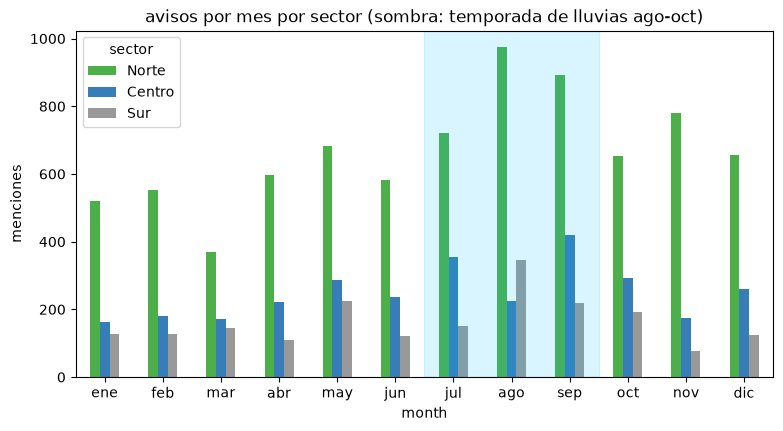

% de menciones ago-oct por sector: {'Centro': '33.4%', 'Norte': '32.4%', 'Sur': '36.5%'} | global: 33.3%


In [254]:
# distribucion mensual de avisos por sector (todos los anios agrupados)
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

por_mes = (
    avisos_ns.groupby(["month", "sector"]).size().unstack("sector")
    .reindex(range(1, 13))[orden]
)

fig, ax = plt.subplots(figsize=(9, 4.5))
por_mes.plot.bar(ax=ax, rot=0, color=[colores_sector[s] for s in orden])
ax.axvspan(6.5 - 1, 9.5 - 1, color="deepskyblue", alpha=0.15)  # ago-oct
ax.set_xticklabels(MESES)
ax.set_title("avisos por mes por sector (sombra: temporada de lluvias ago-oct)")
ax.set_ylabel("menciones")
plt.show()

lluvias = avisos_ns["month"].between(7, 9)
print(
    "% de menciones ago-oct por sector:",
    avisos_ns.groupby("sector").apply(
        lambda d: f"{d['month'].between(7, 9).mean() * 100:.1f}%", include_groups=False
    ).to_dict(),
    "| global:", f"{lluvias.mean() * 100:.1f}%",
)

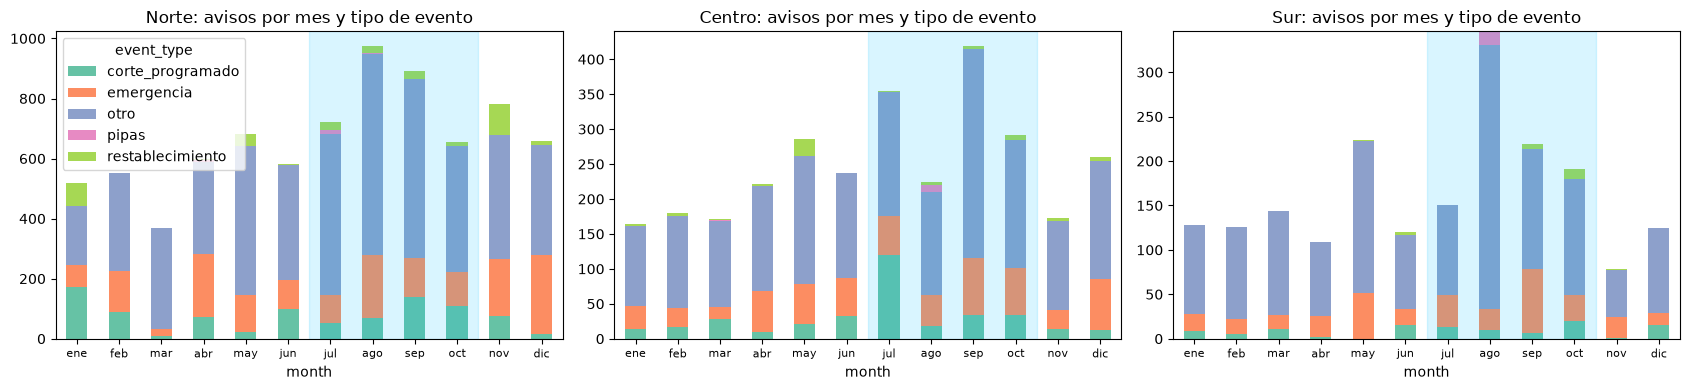

In [261]:
# ¿el patron mensual viene de las emergencias o del ruido administrativo ('otro')?
# color fijo por event_type: sin el, cada panel reasigna Set2 segun sus
# columnas presentes y el mismo color significa cosas distintas entre sectores
TIPOS_EVENTO = ["corte_programado", "emergencia", "otro", "pipas", "restablecimiento"]
COLORES_EVENTO = {
    "corte_programado": "#66c2a5",
    "emergencia": "#fc8d62",
    "otro": "#8da0cb",
    "pipas": "#e78ac3",
    "restablecimiento": "#a6d854",
}

fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=False)
for i, (ax, s) in enumerate(zip(axes, orden)):
    d = avisos_ns[avisos_ns["sector"] == s]
    (
        d.groupby(["month", "event_type"]).size().unstack("event_type")
        .reindex(range(1, 13)).reindex(columns=TIPOS_EVENTO, fill_value=0)
        .plot.bar(ax=ax, rot=0, stacked=True, legend=(i == 0),
                  color=[COLORES_EVENTO[t] for t in TIPOS_EVENTO])
    )
    ax.axvspan(6.5 - 1, 10.5 - 1, color="deepskyblue", alpha=0.15)
    ax.set_xticklabels(MESES, fontsize=8)
    ax.set_title(f"{s}: avisos por mes y tipo de evento")
plt.tight_layout()
plt.show()

menciones por anio y mes:
      ene  feb  mar  abr  may  jun  jul  ago  sep  oct  nov  dic
year                                                            
2021  123  116   96   94  187   58   96   48   98  207  218  168
2022  211   80  156  155  140  198  183  372   64   92  123  161
2023  186  186  123  129  244  106  197   66  521   72  208  236
2024  150  291   59   76  122  206  286  336  212  331  197  144
2025  142  186  252  475  499  370  464  723  635  435  286  333

% jul-sep por anio: {2021: 16.0, 2022: 32.0, 2023: 34.5, 2024: 34.6, 2025: 38.0}


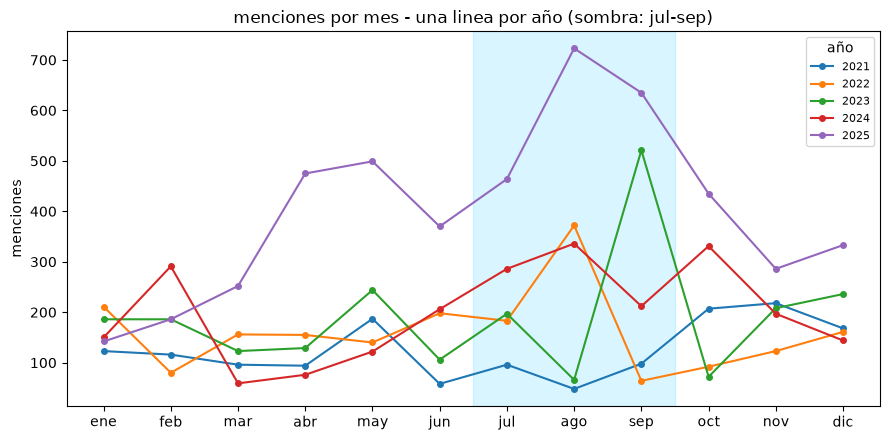

In [262]:
# ¿el patron se repite cada anio o es un solo periodo lluvioso?
por_anio_mes = (
    avisos_ns.groupby(["year", "month"]).size().unstack("month").reindex(columns=range(1, 13))
)
por_anio_mes.columns = MESES
por_anio_mes = por_anio_mes.fillna(0).astype(int)
print("menciones por anio y mes:")
print(por_anio_mes)
print()
print(
    "% jul-sep por anio:",
    (por_anio_mes[["jul","ago", "sep"]].sum(axis=1) / por_anio_mes.sum(axis=1) * 100)
    .round(1)
    .to_dict(),
)

# una linea por año: ¿la temporada jul-sep se repite o fue un solo año?
fig, ax = plt.subplots(figsize=(9, 4.5))
for a, fila in por_anio_mes.iterrows():
    ax.plot(range(1, 13), fila.values, marker="o", markersize=4, label=a)
ax.axvspan(7.5 - 1, 10.5 - 1, color="deepskyblue", alpha=0.15)  # jul-sep
ax.set_xticks(range(1, 13), MESES)
ax.set_title("menciones por mes - una linea por año (sombra: jul-sep)")
ax.set_ylabel("menciones")
ax.legend(title="año", fontsize=8)
plt.tight_layout()
plt.show()

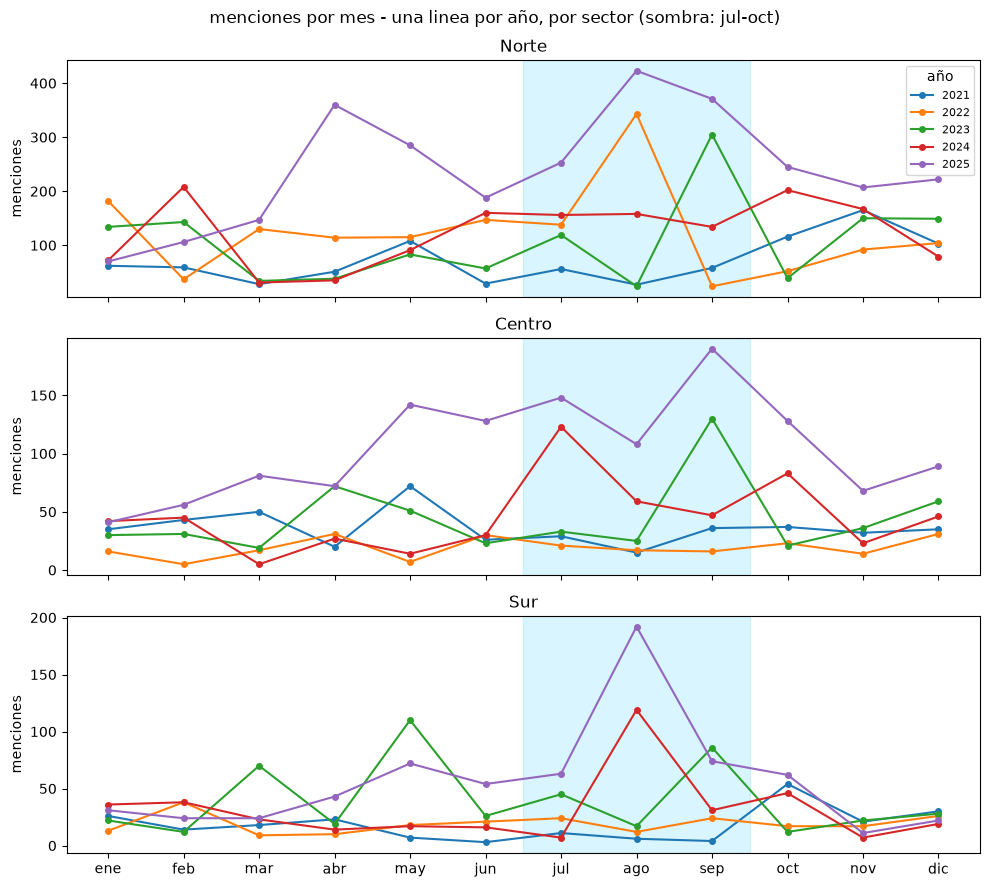

In [263]:
# mismo desglose por sector: una fila por sector, una linea por año
# (eje y independiente por panel: Norte aplasta Centro y Sur si se comparte)
sector_anio_mes = (
    avisos_ns.groupby(["sector", "year", "month"]).size().unstack("month")
    .reindex(columns=range(1, 13)).fillna(0).astype(int)
)

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, s in zip(axes, orden):
    d = sector_anio_mes.loc[s]
    for a, fila in d.iterrows():
        ax.plot(range(1, 13), fila.values, marker="o", markersize=4, label=a)
    ax.axvspan(7.5 - 1, 10.5 - 1, color="deepskyblue", alpha=0.15)  # jul-oct
    ax.set_title(s)
    ax.set_ylabel("menciones")
axes[0].legend(title="año", fontsize=8)
axes[-1].set_xticks(range(1, 13), MESES)
fig.suptitle("menciones por mes - una linea por año, por sector (sombra: jul-oct)")
plt.tight_layout()
plt.show()

menciones en 2025: 4800


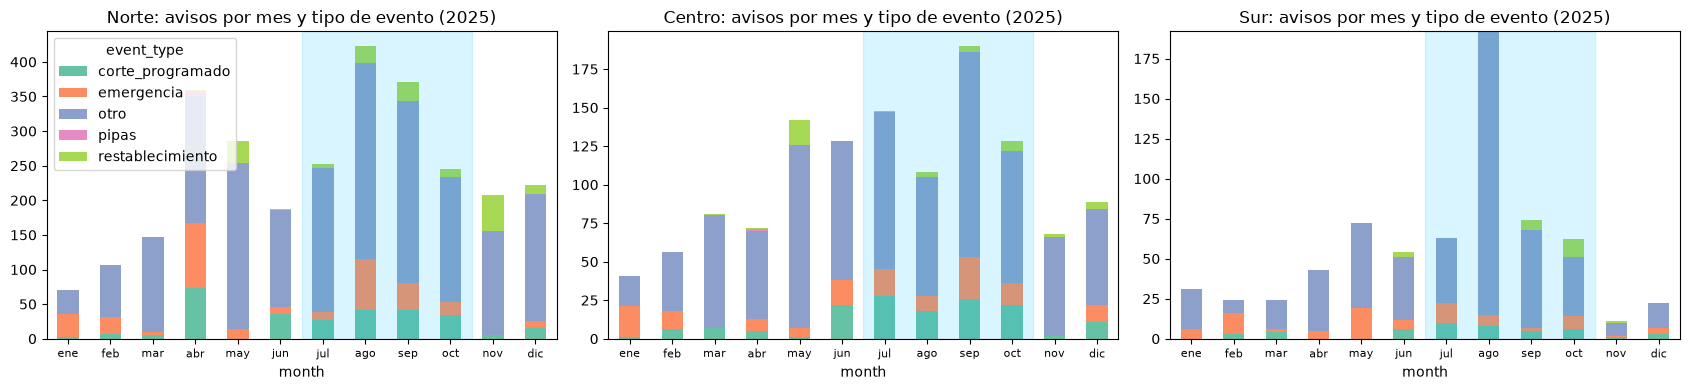

In [264]:
# mismo panel por sector x tipo de evento, solo 2025
avisos_2025 = avisos_ns[avisos_ns["year"] == 2025]
print(f"menciones en 2025: {len(avisos_2025)}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=False)
for i, (ax, s) in enumerate(zip(axes, orden)):
    d = avisos_2025[avisos_2025["sector"] == s]
    (
        d.groupby(["month", "event_type"]).size().unstack("event_type")
        .reindex(range(1, 13)).reindex(columns=TIPOS_EVENTO, fill_value=0)
        .plot.bar(ax=ax, rot=0, stacked=True, legend=(i == 0),
                  color=[COLORES_EVENTO[t] for t in TIPOS_EVENTO])
    )
    ax.axvspan(6.5 - 1, 10.5 - 1, color="deepskyblue", alpha=0.15)
    ax.set_xticklabels(MESES, fontsize=8)
    ax.set_title(f"{s}: avisos por mes y tipo de evento (2025)")
plt.tight_layout()
plt.show()

### Solo emergencias

Las menciones tipo `otro` dominan el volumen y pueden ser ruido administrativo. Se repite el análisis mensual solo con `event_type == "emergencia"` — la firma más cercana a eventos reales de falla/inundación.

menciones de emergencia: 2605 (20.2% del total)


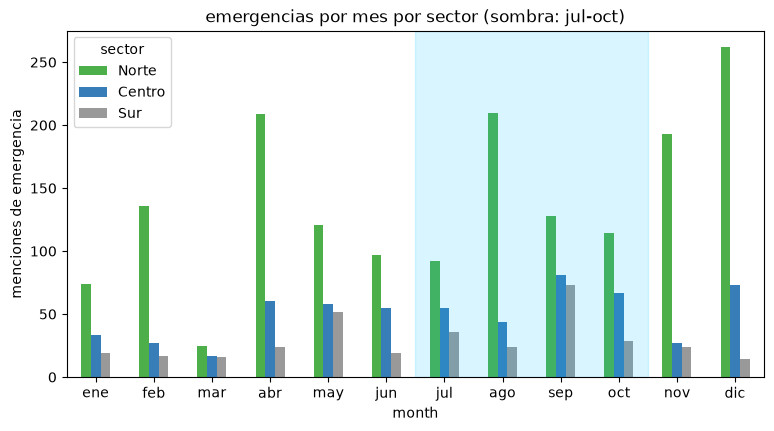

% de emergencias jul-oct por sector: {'Centro': '32.2%', 'Norte': '27.2%', 'Sur': '36.3%'} | global: 29.6%


In [265]:
# solo emergencias: distribucion mensual por sector
emerg_ns = avisos_ns[avisos_ns["event_type"] == "emergencia"]
print(f"menciones de emergencia: {len(emerg_ns)} "
      f"({len(emerg_ns) / len(avisos_ns) * 100:.1f}% del total)")

por_mes_em = (
    emerg_ns.groupby(["month", "sector"]).size().unstack("sector")
    .reindex(range(1, 13))[orden]
)

fig, ax = plt.subplots(figsize=(9, 4.5))
por_mes_em.plot.bar(ax=ax, rot=0, color=[colores_sector[s] for s in orden])
ax.axvspan(6.5 - 1, 10.5 - 1, color="deepskyblue", alpha=0.15)
ax.set_xticklabels(MESES)
ax.set_title("emergencias por mes por sector (sombra: jul-oct)")
ax.set_ylabel("menciones de emergencia")
plt.show()

print(
    "% de emergencias jul-oct por sector:",
    emerg_ns.groupby("sector").apply(
        lambda d: f"{d['month'].between(8, 10).mean() * 100:.1f}%", include_groups=False
    ).to_dict(),
    "| global:", f"{emerg_ns['month'].between(8, 10).mean() * 100:.1f}%",
)

emergencias por anio y mes:
      ene  feb  mar  abr  may  jun  jul  ago  sep  oct  nov  dic
year                                                            
2021   10   22    0    8   61   22   48   11    4   33   55   78
2022    9    6   13   81   13   20   44  129   40    7   27   87
2023   17   23   13   77   75   62   21   15  122   38  107  111
2024   31   80   26   20   43   34   30   33   48   91   54   48
2025   59   49    6  107   39   33   40   90   68   41    1   25

% jul-oct por anio: {2021: 27.3, 2022: 46.2, 2023: 28.8, 2024: 37.5, 2025: 42.8}


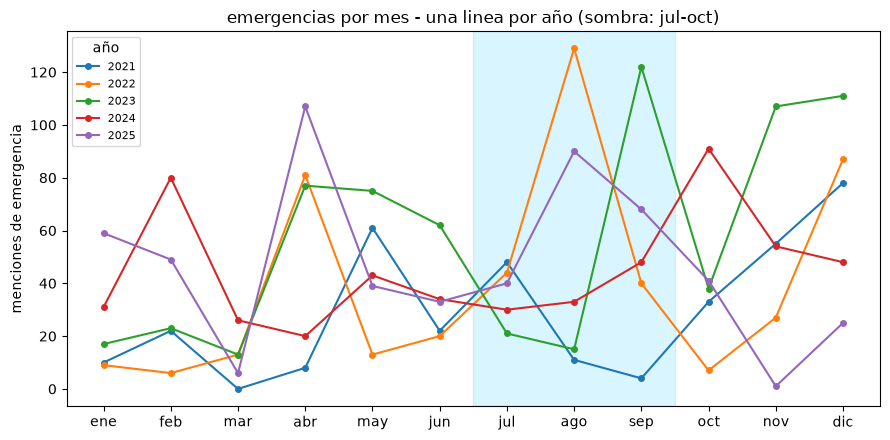

In [266]:
# emergencias por anio y mes: ¿el pico ago-oct se repite?
em_anio_mes = (
    emerg_ns.groupby(["year", "month"]).size().unstack("month").reindex(columns=range(1, 13))
)
em_anio_mes.columns = MESES
em_anio_mes = em_anio_mes.fillna(0).astype(int)
print("emergencias por anio y mes:")
print(em_anio_mes)
print()
print(
    "% jul-oct por anio:",
    (em_anio_mes[["jul","ago", "sep", "oct"]].sum(axis=1) / em_anio_mes.sum(axis=1) * 100)
    .round(1)
    .to_dict(),
)

# una linea por año (solo emergencias)
fig, ax = plt.subplots(figsize=(9, 4.5))
for a, fila in em_anio_mes.iterrows():
    ax.plot(range(1, 13), fila.values, marker="o", markersize=4, label=a)
ax.axvspan(7.5 - 1, 10.5 - 1, color="deepskyblue", alpha=0.15)  # jul-oct
ax.set_xticks(range(1, 13), MESES)
ax.set_title("emergencias por mes - una linea por año (sombra: jul-oct)")
ax.set_ylabel("menciones de emergencia")
ax.legend(title="año", fontsize=8)
plt.tight_layout()
plt.show()